# Coverage (crop, GMM) tutorial
・Kernel: **Python (crystal_seg)**; run cells in order.  
・The steps are shown as a checklist "☐".  
・One cropped image; GMM fit on 10,000 sampled pixels, predict all pixels.  
・EM step example GMM; 2PCA, full-covariance  
・Main process GMM; six-feature, diagonal  
・Outputs: `output/tutorial_001/`  

## 1. Paths and image  
☐ change  OUTPUT_DIR "tutorial_001" to "tutorial_002" or something  
☐ (if you want,) change IMAGE PATH  
☐ run cell

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage import io
from IPython.display import display

WORK_DIR = Path.cwd().resolve()
if not (WORK_DIR / "coverage_tutorial.ipynb").is_file(): WORK_DIR /= "coverage"
if not (WORK_DIR / "coverage_tutorial.ipynb").is_file(): raise FileNotFoundError("Start from coverage/ or the project root.")
PROJECT_ROOT = WORK_DIR.parent
IMAGE_PATH = sorted((PROJECT_ROOT / "data/mag2000/new/pl01").glob("*.jpg"))[0]
OUTPUT_DIR = WORK_DIR / "output" / "tutorial_001"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Image: {IMAGE_PATH}\nTutorial outputs: {OUTPUT_DIR}")

Image: /home/kmanabe2403/dune/data/mag2000/new/pl01/20260806_130816.jpg
Tutorial outputs: /home/kmanabe2403/dune/coverage/output/tutorial_001


## 2. Crop  
☐ run cell  
・Red: crop line

In [2]:
original = io.imread(IMAGE_PATH)
h, w = original.shape[:2]
crop = {"top": 60, "bottom": 100, "left": 60, "right": 100}
image = original[crop["top"]:h-crop["bottom"], crop["left"]:w-crop["right"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(original)
axes[0].add_patch(Rectangle((crop["left"]-.5, crop["top"]-.5), image.shape[1], image.shape[0], fill=False, edgecolor="red", linewidth=1))
axes[0].set_title(f"Before crop: {original.shape[1]} × {original.shape[0]}")
axes[1].imshow(image)
axes[1].set_title(f"After crop: {image.shape[1]} × {image.shape[0]}")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_crop.png", dpi=150)
plt.show()
plt.close(fig)
print(f"Full-resolution analysis image: {image.shape}; no resizing.")
del original

## 3. Pixel features and PCA  
☐ run cell  
・Six pixel features; standardize and reduce to two PCA axes for example drawing.  
・Sampling affects fitting only; all cropped pixels receive predictions.  

In [3]:
from skimage.color import rgb2lab
from scipy.ndimage import gaussian_filter, uniform_filter

# Convert RGB to Lab; normalize lightness L to the range 0–1.
lab = rgb2lab(image).astype(np.float32)
lightness = lab[..., 0] / 100.0
# Brightness is the mean of RGB channels, also scaled to 0–1.
brightness = (image.astype(np.float32) / 255.0).mean(axis=2)
del lab

# One feature map per operation; keep the production order and float32 precision.
# Reflect image boundaries when filtering.
maps = [
    gaussian_filter(lightness, sigma=1, mode="reflect").astype(np.float32),
    gaussian_filter(lightness, sigma=3, mode="reflect").astype(np.float32),
    uniform_filter(lightness, size=5, mode="reflect").astype(np.float32),
    uniform_filter(lightness, size=11, mode="reflect").astype(np.float32),
    uniform_filter(brightness, size=5, mode="reflect").astype(np.float32),
    uniform_filter(brightness, size=11, mode="reflect").astype(np.float32),
]
del lightness, brightness
feature_names = ["L Gaussian σ=1", "L Gaussian σ=3", "L mean 5", "L mean 11", "Brightness mean 5", "Brightness mean 11"]
rng = np.random.default_rng(0)
sample_indices = rng.choice(image.shape[0] * image.shape[1], min(10000, image.shape[0] * image.shape[1]), replace=False)
features = np.column_stack([a.ravel()[sample_indices] for a in maps])
print(f"{len(features):,} sampled pixels × {features.shape[1]} features; GMM fitting uses only this sample.")
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
pca = PCA(n_components=2, random_state=0)
X = pca.fit_transform(scaler.fit_transform(features))
print(f"PCA variance retained: {pca.explained_variance_ratio_.sum():.1%}")
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[:, 0], X[:, 1], s=3, alpha=.3)
ax.set(xlabel="PC1", ylabel="PC2", title="Each point is one sampled pixel")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_pca.png", dpi=150)
plt.show()
plt.close(fig)

## 4. EM progress   
☐ run cell  
☐ if you want to try other settings, you can change N_CLUSTERS  
・One GMM model: initialization → 5 updates → convergence.  
・Crosses: centers; ellipses: 2σ covariance contours.  
・Log likelihood measures fitting progress (not accuracy).  

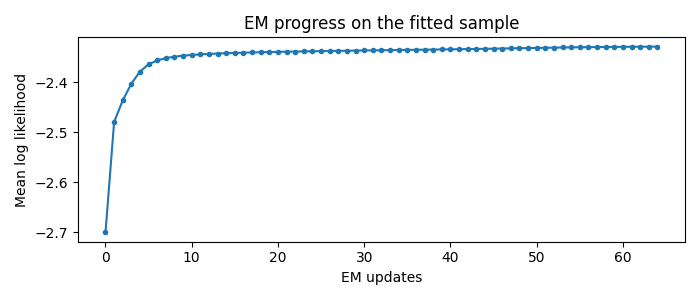

In [ ]:
from copy import deepcopy
import warnings
from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning

N_CLUSTERS = 3  # can use other number; 2 or 4.
# Initialize once, then continue the SAME model one EM update at a time.
initial_means = X[np.random.default_rng(0).choice(len(X), N_CLUSTERS, replace=False)]
gmm = GaussianMixture(N_CLUSTERS, covariance_type="full", random_state=0, n_init=1, init_params="random",
                      means_init=initial_means, weights_init=np.full(N_CLUSTERS, 1 / N_CLUSTERS),
                      reg_covar=1e-5,
                      warm_start=True, max_iter=0, tol=1e-4)
gmm.fit(X)  # Initialization only: zero EM updates.
snapshots = [(0, deepcopy(gmm))]
log_likelihood = [gmm.score(X)]
gmm.max_iter = 1
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)  # One-update fits are intentionally unfinished.
    for iteration in range(1, 501):
        gmm.fit(X)
        log_likelihood.append(gmm.score(X))
        if iteration == 5: snapshots.append((iteration, deepcopy(gmm)))
        if iteration > 5 and gmm.converged_: break
snapshots.append((iteration, deepcopy(gmm)))
print(f"Final iteration: {iteration}; converged: {gmm.converged_}; mean log likelihood: {gmm.score(X):.4f}")

from matplotlib.patches import Ellipse

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
colors = plt.cm.tab10(np.arange(N_CLUSTERS))
for ax, (step, model) in zip(axes, snapshots):
    labels = model.predict(X)
    ax.scatter(X[:, 0], X[:, 1], c=colors[labels], s=7, alpha=.35, rasterized=True)
    for k, (mean, covariance, weight) in enumerate(zip(model.means_, model.covariances_, model.weights_)):
        values, vectors = np.linalg.eigh(covariance)
        order = np.argsort(values)[::-1]
        values, vectors = values[order], vectors[:, order]
        angle = np.degrees(np.arctan2(vectors[1, 0], vectors[0, 0]))
        strength = weight
        ax.add_patch(Ellipse(mean, 4 * np.sqrt(values[0]), 4 * np.sqrt(values[1]), angle=angle,
                             fill=False, edgecolor=colors[k], linewidth=.6 + 5 * strength, alpha=.2 + .8 * strength))
        ax.scatter(*mean, marker="x", s=65, color=colors[k], linewidth=2)
        ax.annotate(f" C{k}: w={weight:.2f}", mean, fontsize=8)
    title = "Initialization (0 EM updates)" if step == 0 else f"After {step} EM updates"
    if step == snapshots[-1][0]: title += " (converged)" if model.converged_ else " (iteration limit)"
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
# Fix one view across snapshots; ellipses can extend outside the observed-data range.
low, high = X.min(axis=0), X.max(axis=0)
pad = np.maximum((high - low) * .08, .1)
axes[0].set(xlim=(low[0]-pad[0], high[0]+pad[0]), ylim=(low[1]-pad[1], high[1]+pad[1]))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_em_steps.png", dpi=150)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.arange(len(log_likelihood)), log_likelihood, marker=".")
ax.set(xlabel="EM updates", ylabel="Mean log likelihood", title="EM progress on the fitted sample")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_em_progress.png", dpi=120)
plt.show()
plt.close(fig)

## 5. Empty clusters and coverage measurement  
☐ run cell    
☐ Inspect the overlay plot and identify the clusters representing empty regions.  
☐ Set `EMPTY_CLUSTERS` to their cluster IDs.(example is "2")  
☐ rerun the cell
・Coverage = 1 − empty pixel fraction.   
・Area fractions are calculated from the number of pixels assigned to each cluster.  
・The result is approximate, but it provides an estimate of coverage.  

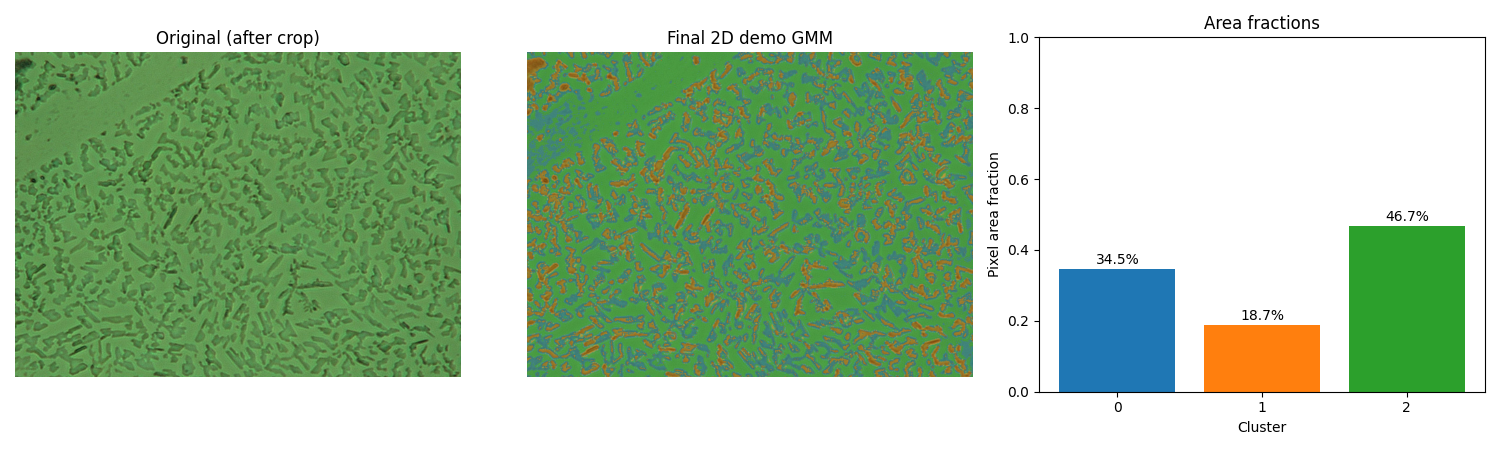

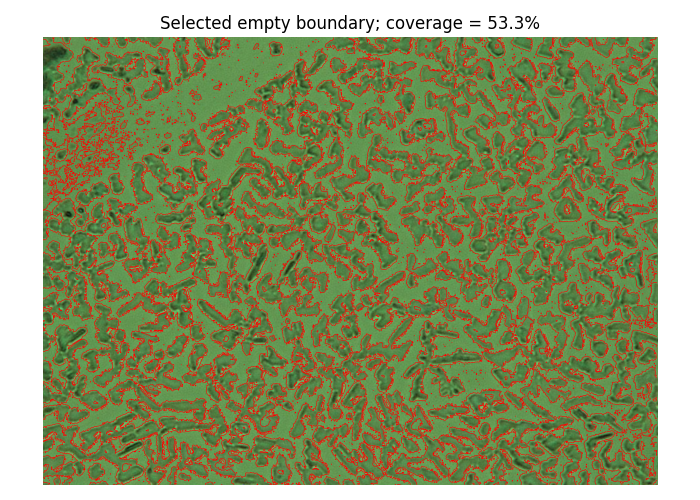

In [5]:
from matplotlib.colors import ListedColormap

# Fit on sampled pixels, then predict EVERY pixel at the original cropped resolution.
n_pixels = image.shape[0] * image.shape[1]
cluster_map = np.empty(n_pixels, dtype=np.uint8)
confidence_map = np.empty(n_pixels, dtype=np.float32)
for start in range(0, n_pixels, 200000):
    end = min(start + 200000, n_pixels)
    chunk = np.column_stack([a.ravel()[start:end] for a in maps])
    probability = gmm.predict_proba(pca.transform(scaler.transform(chunk)))
    cluster_map[start:end] = probability.argmax(axis=1)
    confidence_map[start:end] = probability.max(axis=1)
cluster_map = cluster_map.reshape(image.shape[:2])
confidence_map = confidence_map.reshape(image.shape[:2])
del chunk, probability
counts = np.bincount(cluster_map.ravel(), minlength=N_CLUSTERS)
area = counts / counts.sum()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(image)
axes[0].set_title("Original (after crop)")
axes[1].imshow(image)
axes[1].imshow(cluster_map, cmap=ListedColormap(colors), alpha=.45, vmin=0, vmax=N_CLUSTERS-1)
axes[1].set_title("Final 2D demo GMM")
axes[2].bar(np.arange(N_CLUSTERS), area, color=colors)
axes[2].set(xlabel="Cluster", ylabel="Pixel area fraction", xticks=np.arange(N_CLUSTERS), ylim=(0, 1), title="Area fractions")
for k, value in enumerate(area): axes[2].text(k, value + .015, f"{value:.1%}", ha="center")
for ax in axes[:2]: ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_maps_and_areas.png", dpi=150)
plt.show()
plt.close(fig)
np.savez_compressed(OUTPUT_DIR / "demo_maps.npz", cluster_map=cluster_map, confidence_map=confidence_map, area=area)

EMPTY_CLUSTERS = [2]  # Example syntax: [0] or [0, 2]; choose only after inspecting this demo.
if not EMPTY_CLUSTERS:
    print("Choose the empty clusters above to calculate this image's demo coverage.")
else:
    if len(set(EMPTY_CLUSTERS)) != len(EMPTY_CLUSTERS) or any(k not in range(N_CLUSTERS) for k in EMPTY_CLUSTERS):
        raise ValueError("Use unique cluster IDs from the plotted demo.")
    empty_mask = np.isin(cluster_map, EMPTY_CLUSTERS)
    coverage = 1 - empty_mask.mean()
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.imshow(image)
    ax.contour(empty_mask.astype(float), levels=[.5], colors="red", linewidths=.4)
    ax.set_title(f"Selected empty boundary; coverage = {coverage:.1%}")
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "07_empty_selection.png", dpi=120)
    plt.show()
    plt.close(fig)
    pd.DataFrame([{"empty_clusters": ",".join(map(str, EMPTY_CLUSTERS)), "coverage": coverage}]).to_csv(OUTPUT_DIR / "demo_coverage.csv", index=False)

# Appendix  
## A. Maximum posterior probability  
☐ run cell  
・Bright means a more decisive GMM assignment; confidence is not measured accuracy.

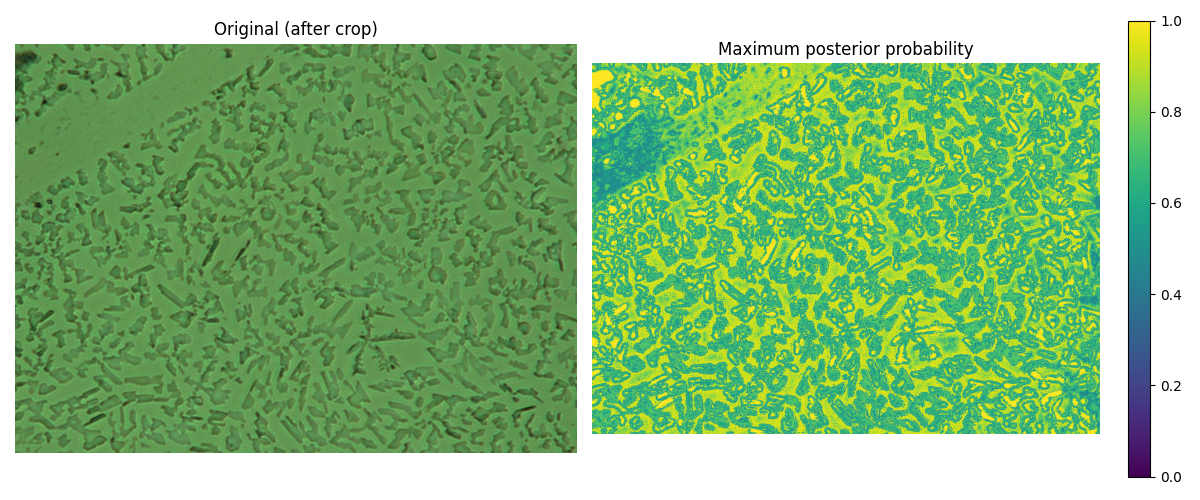

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title("Original (after crop)")
im = axes[1].imshow(confidence_map, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Maximum posterior probability")
fig.colorbar(im, ax=axes[1], fraction=.046)
for ax in axes: ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "08_maximum_posterior.png", dpi=150)
plt.show()
plt.close(fig)

## B. Confidence histograms  
☐ run cell  
・2×2 panels: all pixels, then classes 1–3 (clusters 0–2).  
・example result; we can see class 3 has high confidence, class 1 has very low confidence.

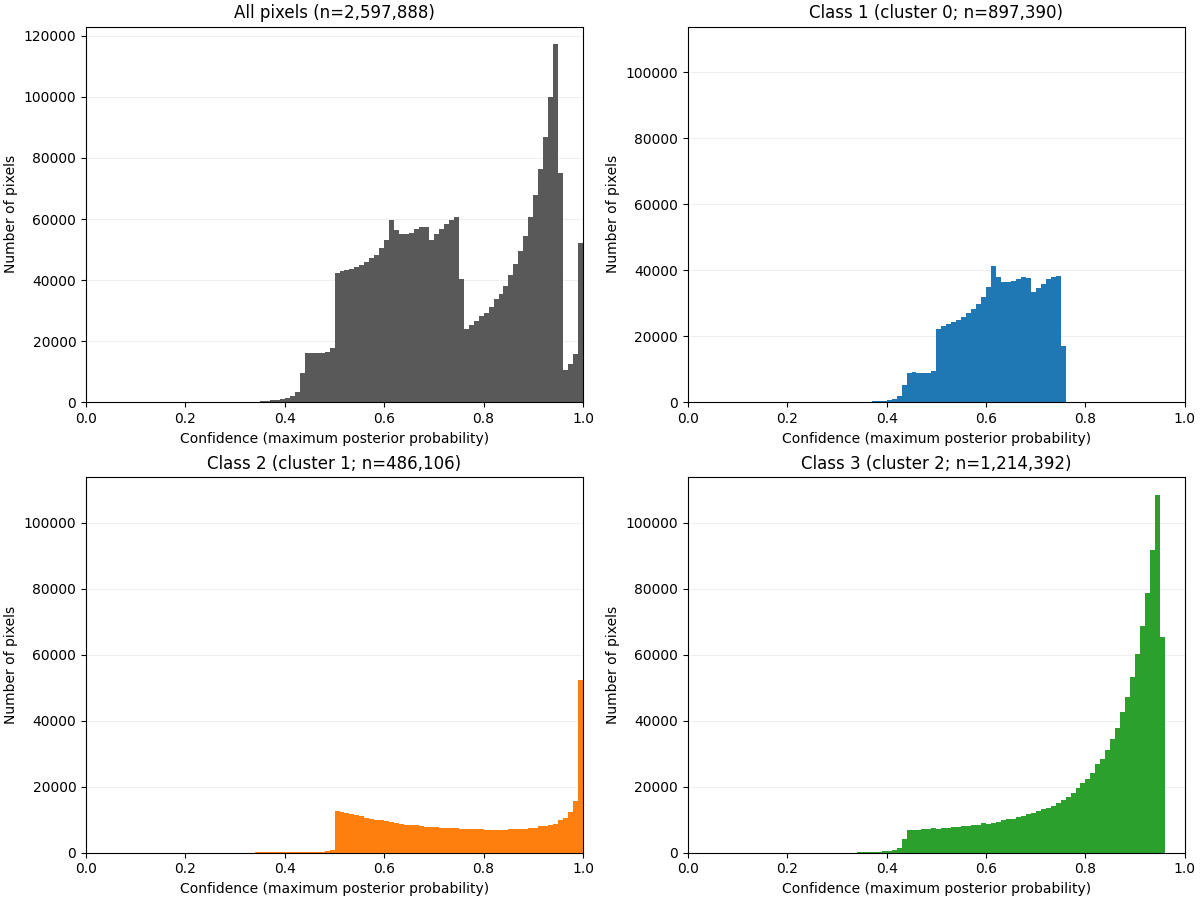

In [7]:
bins = np.linspace(0, 1, 101)
fig = plt.figure(figsize=(12, 9), layout="constrained")
grid = fig.add_gridspec(2, 2)
all_ax = fig.add_subplot(grid[0, 0])
all_counts, _ = np.histogram(confidence_map, bins=bins)
all_ax.bar(bins[:-1], all_counts, width=np.diff(bins), align="edge", color="0.35")
all_ax.set_title(f"All pixels (n={confidence_map.size:,})")
class_axes, class_counts, rows = [], [], []
for k in range(N_CLUSTERS):
    values = confidence_map[cluster_map == k]
    counts, _ = np.histogram(values, bins=bins)
    ax = fig.add_subplot(grid[(k+1)//2, (k+1)%2], sharey=class_axes[0] if class_axes else None)
    ax.bar(bins[:-1], counts, width=np.diff(bins), align="edge", color=colors[k])
    ax.set_title(f"Class {k+1} (cluster {k}; n={len(values):,})")
    class_axes.append(ax)
    class_counts.append(counts)
    rows.extend({"class": k+1, "cluster": k, "confidence_lower_edge": lo, "confidence_upper_edge": hi,
                 "pixel_count": int(count)} for lo, hi, count in zip(bins[:-1], bins[1:], counts))
for ax in [all_ax, *class_axes]:
    ax.set(xlabel="Confidence (maximum posterior probability)", ylabel="Number of pixels", xlim=(0, 1))
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
fig.savefig(OUTPUT_DIR / "09_confidence_distributions.png", dpi=150)
plt.show()
plt.close(fig)
pd.DataFrame(rows).to_csv(OUTPUT_DIR / "confidence_histograms_by_class.csv", index=False)
pd.DataFrame({"confidence_lower_edge": bins[:-1], "confidence_upper_edge": bins[1:],
              "pixel_count": all_counts}).to_csv(OUTPUT_DIR / "confidence_histogram_all.csv", index=False)

## F. Probability margins  
☐ run cell  
・Margin = highest probability − runner-up probability.  
・Small margins indicate competing assignments, not measured errors.  
・Three class-pair histograms; normalized counts, shared scale.  
・example result: class 1-2 margin is rather low, class 1 & 2 might be difficult to distinguish.

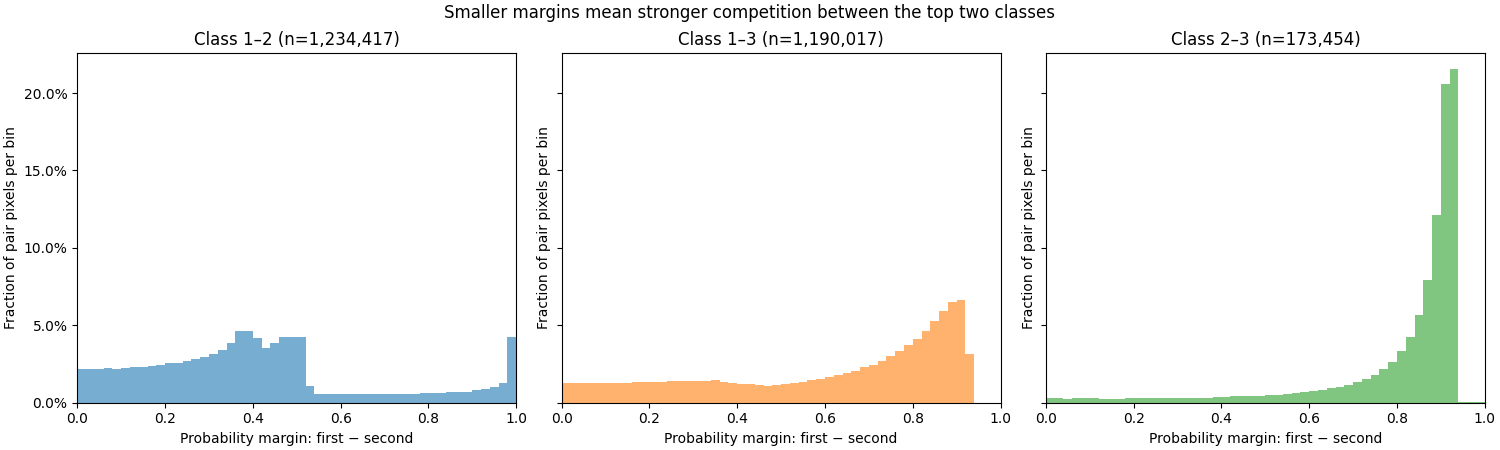

In [8]:
from itertools import combinations
from matplotlib.ticker import PercentFormatter

margin_bins = np.linspace(0, 1, 51)
pairs = list(combinations(range(N_CLUSTERS), 2))
pair_histograms = np.zeros((len(pairs), len(margin_bins)-1), dtype=np.int64)
for start in range(0, image.shape[0] * image.shape[1], 200000):
    end = min(start + 200000, image.shape[0] * image.shape[1])
    chunk = np.column_stack([a.ravel()[start:end] for a in maps])
    probability = gmm.predict_proba(pca.transform(scaler.transform(chunk)))
    first = probability.argmax(axis=1)
    first_probability = probability[np.arange(len(first)), first].copy()
    probability[np.arange(len(first)), first] = -np.inf
    second = probability.argmax(axis=1)
    margin = first_probability - probability[np.arange(len(first)), second]
    for j, (a, b) in enumerate(pairs):
        mask = ((first == a) & (second == b)) | ((first == b) & (second == a))
        pair_histograms[j] += np.histogram(margin[mask], bins=margin_bins)[0]
pair_totals = pair_histograms.sum(axis=1)
fig, axes = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4.5), squeeze=False, sharey=True, layout="constrained")
labels, histogram_rows = [], []
for j, ((a, b), ax) in enumerate(zip(pairs, axes.flat)):
    label = f"Class {a+1}–{b+1}"
    labels.append(label)
    fractions = pair_histograms[j] / pair_totals[j] if pair_totals[j] else np.zeros(len(margin_bins)-1)
    ax.stairs(fractions, margin_bins, fill=True, alpha=.6, color=f"C{j % 10}")
    ax.set(title=f"{label} (n={pair_totals[j]:,})", xlabel="Probability margin: first − second", ylabel="Fraction of pair pixels per bin", xlim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    histogram_rows.extend({"pair": label, "margin_lower_edge": lo, "margin_upper_edge": hi,
                           "pixel_count": int(count), "fraction_within_pair": fraction} for lo, hi, count, fraction in zip(margin_bins[:-1], margin_bins[1:], pair_histograms[j], fractions))
axes[0, 0].set_ylim(bottom=0)
fig.suptitle("Smaller margins mean stronger competition between the top two classes")
fig.savefig(OUTPUT_DIR / "13_probability_margins.png", dpi=150)
plt.show()
plt.close(fig)
pd.DataFrame(histogram_rows).to_csv(OUTPUT_DIR / "probability_margin_histograms.csv", index=False)
margin_summary = pd.DataFrame({"pair": labels, "n_pixels": pair_totals})
margin_summary.to_csv(OUTPUT_DIR / "probability_margin_summary.csv", index=False)
del chunk, probability

## D. Clear versus ambiguous features  
☐ run cell  
・Per class: top/bottom 10% of confidence define clear/ambiguous pixels.  
・Solid/dotted lines; sample up to 5,000 pixels per class/group.  
・Shared feature bins, unit-area curves; ties can exceed 10%.  
・Distributions describe associations, not causes of errors.  
・I'm not sure how we can use this plot, but we can investigate something like feature importance, the reason why class 1-2 are confused.

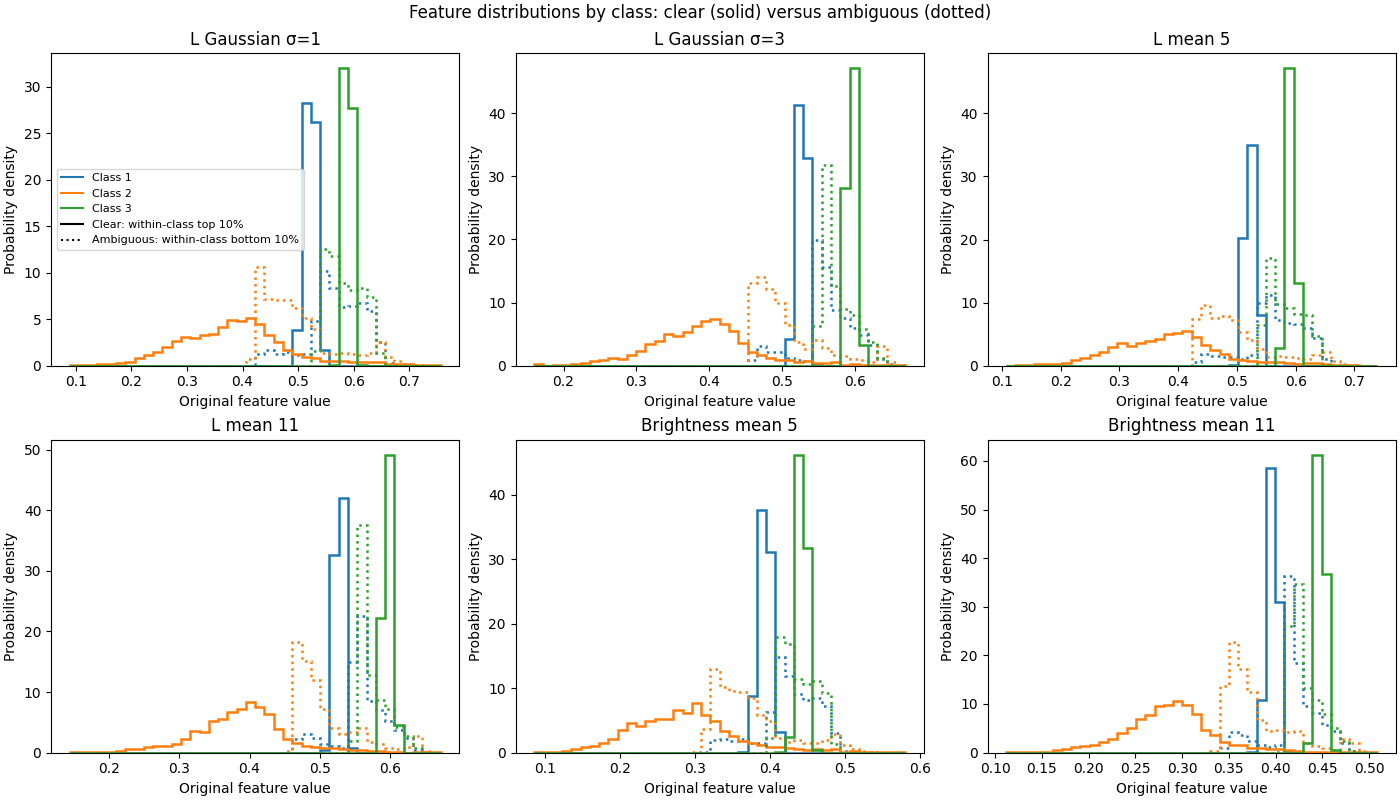

,class,group,confidence_cutoff,n_pixels,sampled_pixels
0,1,Ambiguous,0.511336,89739,5000
1,1,Clear,0.730973,89739,5000
2,2,Ambiguous,0.536589,48611,5000
3,2,Clear,0.991798,48611,5000
4,3,Ambiguous,0.590747,121440,5000
5,3,Clear,0.945105,121440,5000


In [9]:
from matplotlib.lines import Line2D

rng = np.random.default_rng(0)
groups, summary = [], []
for k in range(N_CLUSTERS):
    indices = np.flatnonzero(cluster_map.ravel() == k)
    if not len(indices): continue
    confidence = confidence_map.ravel()[indices]
    low, high = np.quantile(confidence, [.10, .90])
    if high <= low:
        print(f"Class {k+1}: confidence does not separate low/high groups; skipped.")
        continue
    for name, mask, style, cutoff in [("Ambiguous", confidence <= low, ":", low), ("Clear", confidence >= high, "-", high)]:
        candidates = indices[mask]
        selected = rng.choice(candidates, min(5000, len(candidates)), replace=False)
        values = np.column_stack([a.ravel()[selected] for a in maps])
        groups.append((k, name, style, values))
        summary.append({"class": k+1, "group": name, "confidence_cutoff": cutoff, "n_pixels": len(candidates), "sampled_pixels": len(selected)})
if not groups: raise ValueError("No classes have separable confidence groups.")
fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")
distributions = []
for feature, ax in enumerate(axes.flat):
    lo = min(values[:, feature].min() for _, _, _, values in groups)
    hi = max(values[:, feature].max() for _, _, _, values in groups)
    bins = np.linspace(float(lo), float(hi if hi > lo else lo + 1e-6), 41)
    for k, name, style, values in groups:
        density, _ = np.histogram(values[:, feature].astype(float), bins=bins, density=True)
        ax.stairs(density, bins, color=colors[k], linestyle=style, linewidth=1.8)
        distributions.extend({"feature": feature_names[feature], "class": k+1, "group": name, "lower_edge": lower,
                              "upper_edge": upper, "density": value} for lower, upper, value in zip(bins[:-1], bins[1:], density))
    ax.set(title=feature_names[feature], xlabel="Original feature value", ylabel="Probability density")
handles = [Line2D([], [], color=colors[k], label=f"Class {k+1}") for k in range(N_CLUSTERS)]
handles += [Line2D([], [], color="black", linestyle=style, label=name) for name, style in [("Clear: within-class top 10%", "-"), ("Ambiguous: within-class bottom 10%", ":")]]
axes.flat[0].legend(handles=handles, fontsize=8)
fig.suptitle("Feature distributions by class: clear (solid) versus ambiguous (dotted)")
fig.savefig(OUTPUT_DIR / "11_ambiguous_clear_features.png", dpi=150)
plt.show()
plt.close(fig)
pd.DataFrame(distributions).to_csv(OUTPUT_DIR / "ambiguous_clear_feature_distributions.csv", index=False)
display(pd.DataFrame(summary))
pd.DataFrame(summary).to_csv(OUTPUT_DIR / "ambiguous_clear_class_composition.csv", index=False)